In [2]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split

df = pd.read_csv("student_performance_dataset.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  1000 non-null   int64  
 1   gender                      1000 non-null   str    
 2   study_time_hours            1000 non-null   float64
 3   attendance_percent          1000 non-null   float64
 4   sleep_hours                 1000 non-null   float64
 5   parental_education          898 non-null    str    
 6   internet_access             1000 non-null   str    
 7   extracurricular_activities  1000 non-null   str    
 8   part_time_job               1000 non-null   str    
 9   previous_grade              1000 non-null   float64
 10  final_exam_score            1000 non-null   float64
 11  final_grade                 1000 non-null   str    
dtypes: float64(5), int64(1), str(6)
memory usage: 115.4 KB


In [3]:
df.head()

,student_id,gender,study_time_hours,attendance_percent,sleep_hours,parental_education,internet_access,extracurricular_activities,part_time_job,previous_grade,final_exam_score,final_grade
0,1,Male,4.0,98.0,6.5,Bachelors,Yes,Yes,No,76.9,100.0,A
1,2,Female,6.3,100.0,5.7,High School,Yes,Yes,Yes,75.5,100.0,A
2,3,Male,4.9,85.3,7.9,Bachelors,Yes,No,Yes,88.5,97.3,A
3,4,Male,2.6,77.5,8.0,NaN,Yes,Yes,No,85.1,83.8,B
4,5,Male,2.2,89.6,4.6,Bachelors,Yes,No,Yes,61.8,68.3,D


In [4]:
df.isnull()

,student_id,gender,study_time_hours,attendance_percent,sleep_hours,parental_education,internet_access,extracurricular_activities,part_time_job,previous_grade,final_exam_score,final_grade
0,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,True,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...
995,False,False,False,False,False,False,False,False,False,False,False,False
996,False,False,False,False,False,True,False,False,False,False,False,False
997,False,False,False,False,False,False,False,False,False,False,False,False
998,False,False,False,False,False,False,False,False,False,False,False,False


In [5]:
df['parental_education'] = df['parental_education'].fillna('nessuna_istruzione')

In [6]:
df["parental_education"].value_counts()

parental_education
High School           356
Bachelors             308
Masters               184
nessuna_istruzione    102
PhD                    50
Name: count, dtype: int64

In [7]:
df = pd.get_dummies(df, columns=['gender', 'internet_access', 'extracurricular_activities', 'part_time_job'], drop_first=True)

In [8]:
valori = ['nessuna_istruzione', 'High School', 'Bachelors', 'Masters', 'PhD']
df["parental_education"] = df["parental_education"].map({v: i for i, v in enumerate(valori)})

In [9]:
df["final_grade"].value_counts()

final_grade
B    354
A    284
C    261
D     89
F     12
Name: count, dtype: int64

In [10]:
ordine_voti = ['F', 'D', 'C', 'B', 'A']
df['final_grade'] = df['final_grade'].map({v: i for i, v in enumerate(ordine_voti)})

In [11]:
df['final_grade'].value_counts()

final_grade
3    354
4    284
2    261
1     89
0     12
Name: count, dtype: int64

In [12]:
df.groupby('final_grade')['final_exam_score'].agg(['min', 'max'])

,min,max
final_grade,,
0,46.8,59.7
1,60.0,69.9
2,70.0,79.9
3,80.0,89.9
4,90.0,100.0


In [13]:
df['final_grade'] = df['final_grade'].replace({0: 1})

In [14]:
df['final_grade'].value_counts()

final_grade
3    354
4    284
2    261
1    101
Name: count, dtype: int64

In [15]:
X = df.drop(columns=['student_id', 'final_grade', 'final_exam_score'])
y = df['final_grade']

In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   student_id                      1000 non-null   int64  
 1   study_time_hours                1000 non-null   float64
 2   attendance_percent              1000 non-null   float64
 3   sleep_hours                     1000 non-null   float64
 4   parental_education              1000 non-null   int64  
 5   previous_grade                  1000 non-null   float64
 6   final_exam_score                1000 non-null   float64
 7   final_grade                     1000 non-null   int64  
 8   gender_Male                     1000 non-null   bool   
 9   internet_access_Yes             1000 non-null   bool   
 10  extracurricular_activities_Yes  1000 non-null   bool   
 11  part_time_job_Yes               1000 non-null   bool   
dtypes: bool(4), float64(5), int64(3)
memory usage:

<Axes: xlabel='final_grade'>

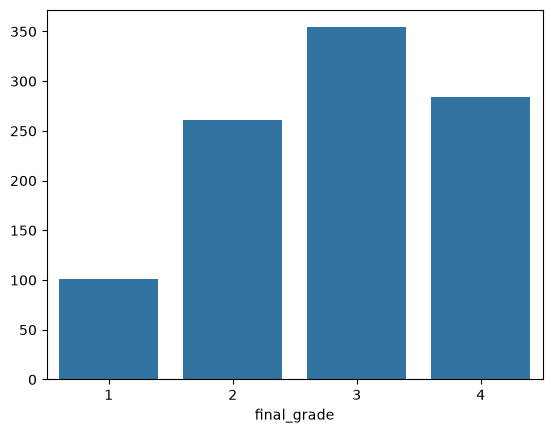

In [17]:
import seaborn as sns

gradeVal = df['final_grade'].value_counts()
sns.barplot(x=gradeVal.index, y=gradeVal.values)

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

In [19]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'min_samples_split': [2, 5, 10],
    'max_depth': [5, 7, 9, 11],
    'criterion': ['gini', 'entropy', 'log_loss'],
}

random_search = RandomizedSearchCV(
    DecisionTreeClassifier(class_weight='balanced', random_state=42),
    param_dist, n_iter=15, cv=5, scoring='accuracy', random_state=42)
random_search.fit(X_train, y_train)

print(f"Migliori parametri: {random_search.best_params_}")
print(f"Miglior accuracy in CV: {random_search.best_score_:.4f}")


Migliori parametri: {'min_samples_split': 2, 'max_depth': 11, 'criterion': 'entropy'}
Miglior accuracy in CV: 0.4729


In [20]:
from sklearn.metrics import classification_report
best_model = random_search.best_estimator_
y_pred = best_model.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           1       0.24      0.26      0.25        31
           2       0.41      0.35      0.38        78
           3       0.41      0.42      0.42       106
           4       0.57      0.61      0.59        85

    accuracy                           0.44       300
   macro avg       0.41      0.41      0.41       300
weighted avg       0.44      0.44      0.44       300



In [21]:
clf = DecisionTreeClassifier(min_samples_split=2, max_depth=11, criterion='entropy', class_weight='balanced', random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           1       0.24      0.26      0.25        31
           2       0.41      0.35      0.38        78
           3       0.41      0.42      0.42       106
           4       0.57      0.61      0.59        85

    accuracy                           0.44       300
   macro avg       0.41      0.41      0.41       300
weighted avg       0.44      0.44      0.44       300

